<a href="https://www.kaggle.com/code/mobeenfatimah/medical-insurance-cost-prediction-linearregression?scriptVersionId=364139873" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

## Insurance Forecast by using Linear Regression
<p>
<span style="background:linear-gradient(90deg,#0f766e,#2dd4bf);color:white;padding:7px 13px;border-radius:18px;"><b>DATA EXPLORATION</b></span>
<span style="background:linear-gradient(90deg,#2563eb,#60a5fa);color:white;padding:7px 13px;border-radius:18px;"><b>LINEAR REGRESSION</b></span>
<span style="background:linear-gradient(90deg,#7c3aed,#c084fc);color:white;padding:7px 13px;border-radius:18px;"><b>MODEL EVALUATION</b></span>
</p>
</div>

> **Objective:** explore personal insurance attributes and build regression models to estimate individual medical insurance charges. This CPU-friendly notebook focuses on transparent Linear Regression, visual analysis, leakage-safe preprocessing, and meaningful regression metrics.

## Notebook roadmap
1. Dataset discovery, loading, and validation
2. Data cleaning and exploratory data analysis
3. Visual analysis of beneficiary attributes and charges
4. Correlation and feature preparation
5. Linear Regression training and evaluation
6. Residual diagnostics and coefficient interpretation
7. Regularized and nonlinear baseline comparison
8. Findings and responsible-use notes

**Dataset:** `mirichoi0218/insurance` · expected file: `insurance.csv`  
**Target:** `charges` — individual medical costs billed by health insurance.  
**Runtime:** CPU only; no GPU, deep learning framework, or paid API.

**Important:** this is a small educational dataset of 1,338 records, not a clinical dataset or validated insurance-pricing system. Results should not be used for real medical, coverage, or pricing decisions.

## 01 · Import libraries

Explore this stage of the insurance-cost regression workflow.

In [1]:
import os, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
SEED=42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"]=(9,5)
print("Environment ready")

Environment ready


## 02 · Find insurance.csv

Review the output and use it to guide the next analysis step.

In [2]:
roots=[Path("/kaggle/input"),Path(".")]
files=[]
for root in roots:
    if root.exists(): files += list(root.rglob("insurance.csv"))
files=list(dict.fromkeys(files))
if not files: raise FileNotFoundError("Attach mirichoi0218/insurance using Kaggle Add Input.")
DATA_PATH=files[0]
print("Using:",DATA_PATH)

Using: /kaggle/input/datasets/mirichoi0218/insurance/insurance.csv


## 03 · Load dataset

Explore this stage of the insurance-cost regression workflow.

In [3]:
df=pd.read_csv(DATA_PATH)
display(df.head())

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 04 · Dataset dimensions

Review the output and use it to guide the next analysis step.

In [4]:
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")

Rows: 1,338 | Columns: 7


## 05 · Column guide

Explore this stage of the insurance-cost regression workflow.

In [5]:
guide=pd.DataFrame({"column":["age","sex","bmi","children","smoker","region","charges"],"description":["Age of beneficiary","Insurance contractor gender","Body mass index","Covered children/dependents","Smoking status","US residential region","Individual medical costs billed"],"role":["Feature"]*6+["Target"]})
display(guide)

,column,description,role
0,age,Age of beneficiary,Feature
1,sex,Insurance contractor gender,Feature
2,bmi,Body mass index,Feature
3,children,Covered children/dependents,Feature
4,smoker,Smoking status,Feature
5,region,US residential region,Feature
6,charges,Individual medical costs billed,Target


## 06 · Data types

Review the output and use it to guide the next analysis step.

In [6]:
df.info()
display(df.dtypes.to_frame("dtype"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


,dtype
age,int64
sex,object
bmi,float64
children,int64
smoker,object
region,object
charges,float64


## 07 · Numerical summary

Explore this stage of the insurance-cost regression workflow.

In [7]:
display(df.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
age,1338.0,39.21,14.05,18.00,27.00,39.00,51.00,64.00
bmi,1338.0,30.66,6.10,15.96,26.30,30.40,34.69,53.13
children,1338.0,1.09,1.21,0.00,0.00,1.00,2.00,5.00
charges,1338.0,13270.42,12110.01,1121.87,4740.29,9382.03,16639.91,63770.43


## 08 · Categorical summary

Review the output and use it to guide the next analysis step.

In [8]:
for c in df.select_dtypes(include="object"):
    print("\\n",c); display(df[c].value_counts(dropna=False).to_frame("count"))

\n sex


,count
sex,
male,676
female,662


\n smoker


,count
smoker,
no,1064
yes,274


\n region


,count
region,
southeast,364
southwest,325
northwest,325
northeast,324


## 09 · Missing values

Explore this stage of the insurance-cost regression workflow.

In [9]:
display(pd.DataFrame({"missing":df.isna().sum(),"percent":(df.isna().mean()*100).round(2)}))

,missing,percent
age,0,0.0
sex,0,0.0
bmi,0,0.0
children,0,0.0
smoker,0,0.0
region,0,0.0
charges,0,0.0


## 10 · Duplicate rows

Review the output and use it to guide the next analysis step.

In [10]:
print("Exact duplicate rows:",df.duplicated().sum())

Exact duplicate rows: 1


## 11 · Normalize column names

Explore this stage of the insurance-cost regression workflow.

In [11]:
df.columns=df.columns.str.strip().str.lower()
print(df.columns.tolist())

['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']


## 12 · Validate schema

Review the output and use it to guide the next analysis step.

In [12]:
required={"age","sex","bmi","children","smoker","region","charges"}
missing=required-set(df.columns)
if missing: raise ValueError(f"Missing columns: {missing}")
print("Required schema verified")

Required schema verified


## 13 · Clean types and missing data

Explore this stage of the insurance-cost regression workflow.

In [13]:
for c in ["age","bmi","children","charges"]: df[c]=pd.to_numeric(df[c],errors="coerce")
for c in ["sex","smoker","region"]: df[c]=df[c].astype("string").str.strip().str.lower()
before=len(df); df=df.dropna(subset=list(required)).copy()
print("Rows retained:",len(df),"of",before)

Rows retained: 1338 of 1338


## 14 · Review category values

Review the output and use it to guide the next analysis step.

In [14]:
for c in ["sex","smoker","region"]: print(c,sorted(df[c].dropna().unique()))

sex ['female', 'male']
smoker ['no', 'yes']
region ['northeast', 'northwest', 'southeast', 'southwest']


## 15 · Dataset snapshot

Explore this stage of the insurance-cost regression workflow.

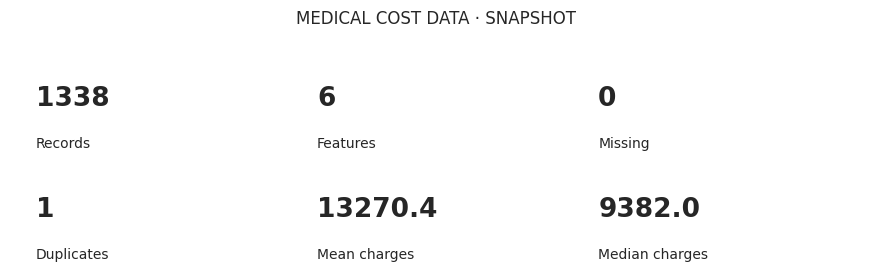

In [15]:
vals=[("Records",len(df)),("Features",6),("Missing",int(df.isna().sum().sum())),("Duplicates",int(df.duplicated().sum())),("Mean charges",round(df.charges.mean(),1)),("Median charges",round(df.charges.median(),1))]
fig,ax=plt.subplots(figsize=(11,3)); ax.axis("off")
for i,(k,v) in enumerate(vals):
    x=.03+(i%3)*.33; y=.68-(i//3)*.48
    ax.text(x,y,str(v),fontsize=19,weight="bold",transform=ax.transAxes)
    ax.text(x,y-.18,k,fontsize=10,transform=ax.transAxes)
    ax.add_patch(plt.Rectangle((x-.015,y-.25),.28,.42,fill=False,transform=ax.transAxes))
plt.title("MEDICAL COST DATA · SNAPSHOT"); plt.show()

## 16 · Age distribution

Review the output and use it to guide the next analysis step.

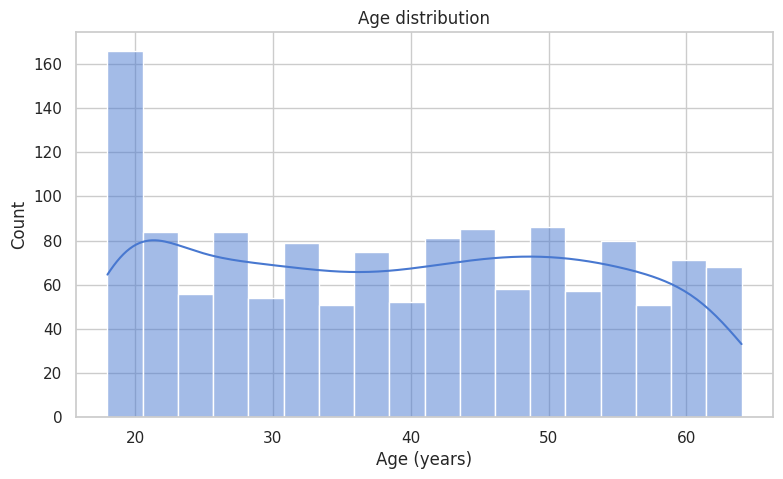

In [16]:
sns.histplot(df.age,bins=18,kde=True); plt.title("Age distribution"); plt.xlabel("Age (years)"); plt.show()

## 17 · BMI distribution

Explore this stage of the insurance-cost regression workflow.

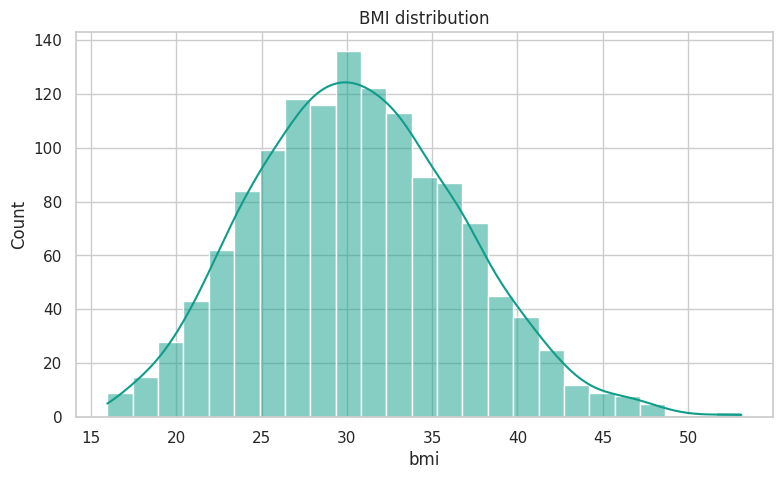

In [17]:
sns.histplot(df.bmi,bins=25,kde=True,color="#0f9d8a"); plt.title("BMI distribution"); plt.show()

## 18 · Charges distribution

Review the output and use it to guide the next analysis step.

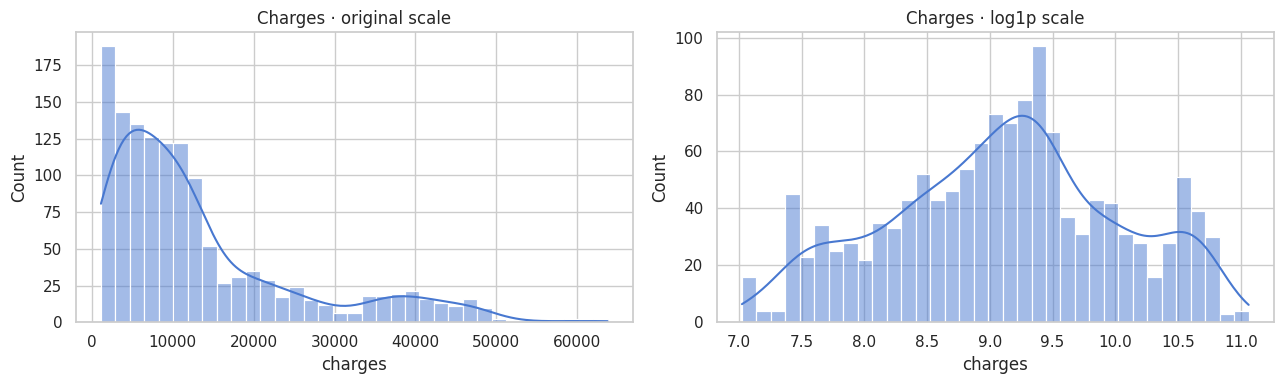

In [18]:
fig,ax=plt.subplots(1,2,figsize=(13,4))
sns.histplot(df.charges,bins=35,kde=True,ax=ax[0]); ax[0].set_title("Charges · original scale")
sns.histplot(np.log1p(df.charges),bins=35,kde=True,ax=ax[1]); ax[1].set_title("Charges · log1p scale")
plt.tight_layout(); plt.show()

## 19 · Beneficiaries by sex

Explore this stage of the insurance-cost regression workflow.

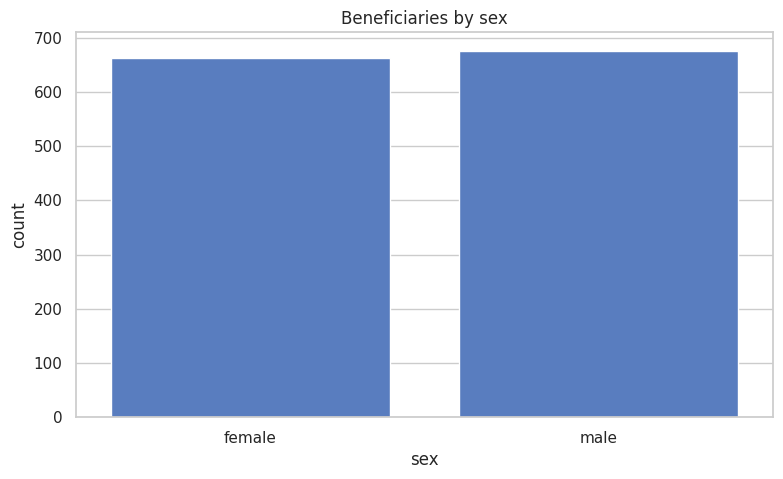

In [19]:
sns.countplot(data=df,x="sex"); plt.title("Beneficiaries by sex"); plt.show()

## 20 · Smoking status

Review the output and use it to guide the next analysis step.

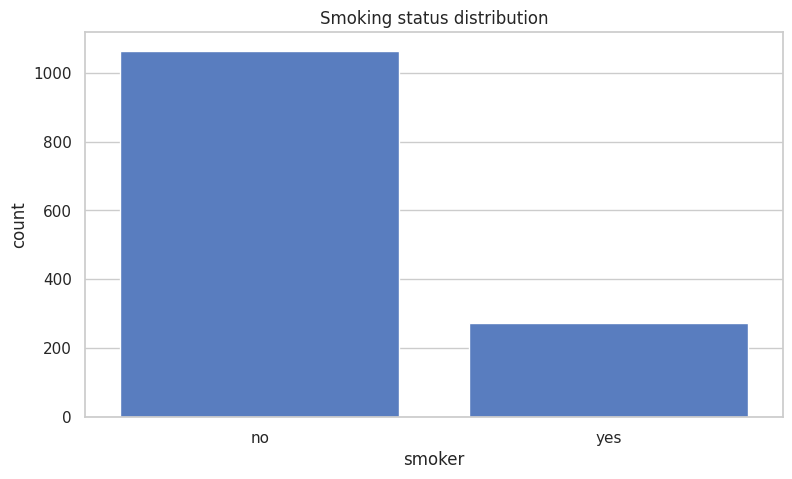

In [20]:
sns.countplot(data=df,x="smoker",order=df.smoker.value_counts().index); plt.title("Smoking status distribution"); plt.show()

## 21 · Region distribution

Explore this stage of the insurance-cost regression workflow.

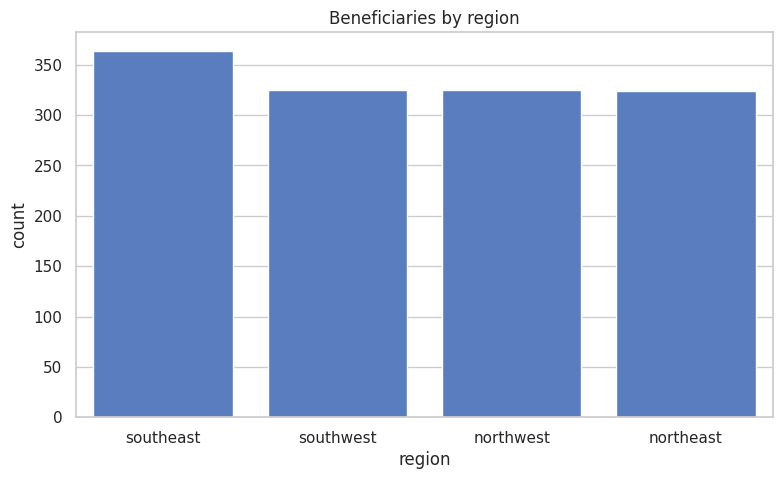

In [21]:
sns.countplot(data=df,x="region",order=df.region.value_counts().index); plt.title("Beneficiaries by region"); plt.show()

## 22 · Covered children distribution

Review the output and use it to guide the next analysis step.

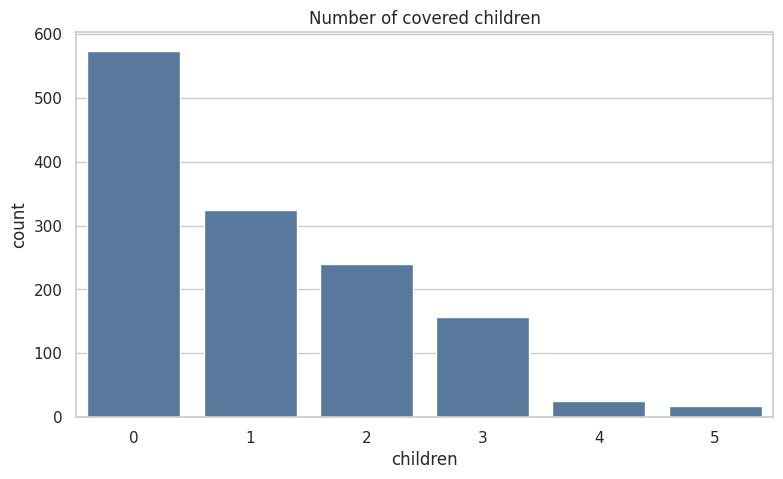

In [22]:
sns.countplot(data=df,x="children",color="#4c78a8"); plt.title("Number of covered children"); plt.show()

## 23 · Charges by smoking status

Explore this stage of the insurance-cost regression workflow.

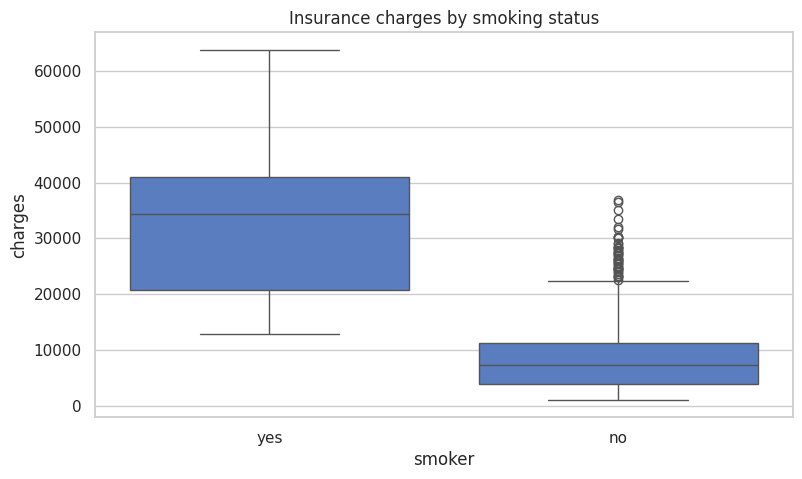

In [23]:
sns.boxplot(data=df,x="smoker",y="charges"); plt.title("Insurance charges by smoking status"); plt.show()

## 24 · Charges by sex

Review the output and use it to guide the next analysis step.

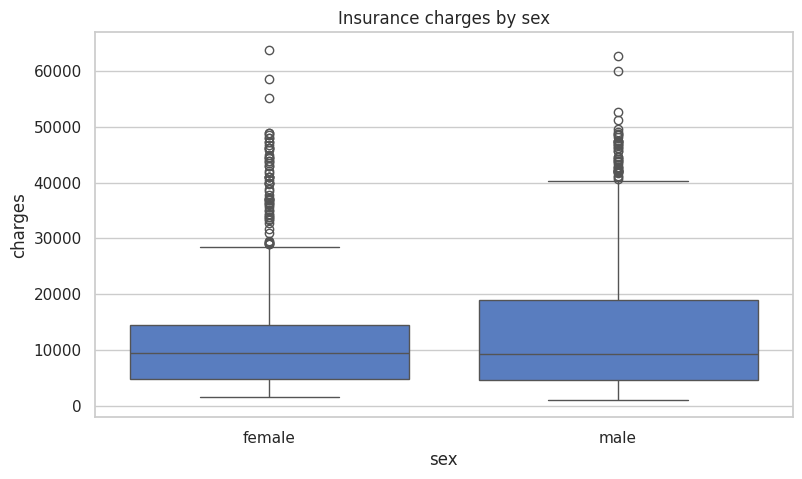

In [24]:
sns.boxplot(data=df,x="sex",y="charges"); plt.title("Insurance charges by sex"); plt.show()

## 25 · Charges by region

Explore this stage of the insurance-cost regression workflow.

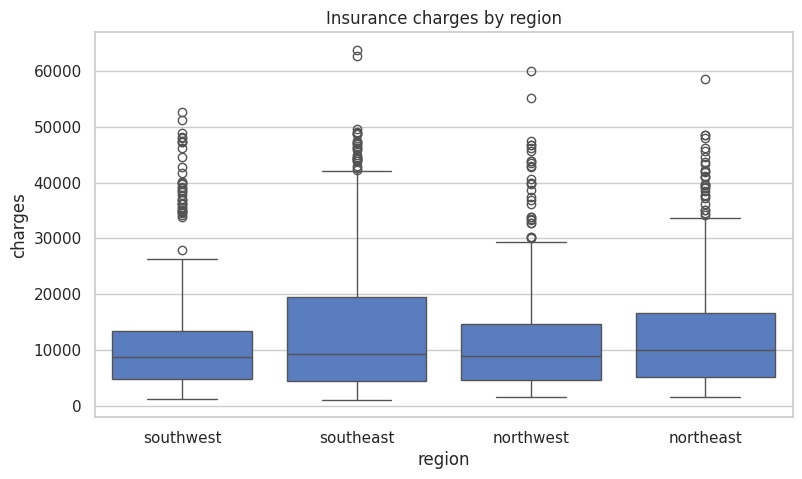

In [25]:
sns.boxplot(data=df,x="region",y="charges"); plt.title("Insurance charges by region"); plt.show()

## 26 · Age vs charges

Review the output and use it to guide the next analysis step.

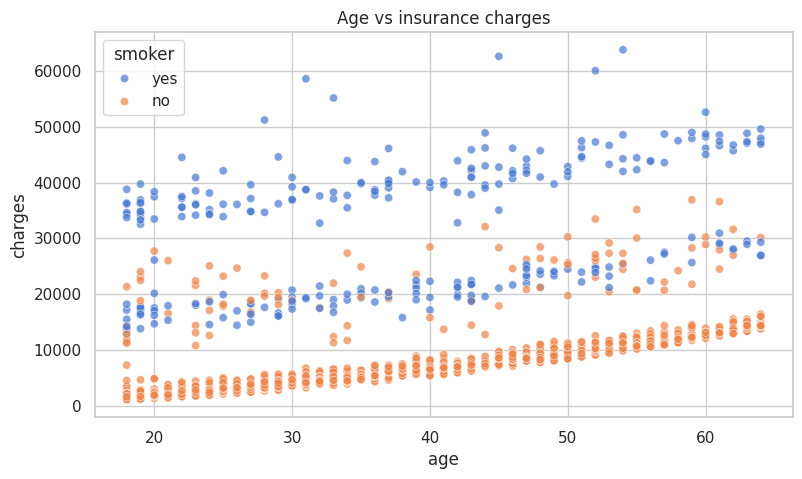

In [26]:
sns.scatterplot(data=df,x="age",y="charges",hue="smoker",alpha=.7); plt.title("Age vs insurance charges"); plt.show()

## 27 · BMI vs charges

Explore this stage of the insurance-cost regression workflow.

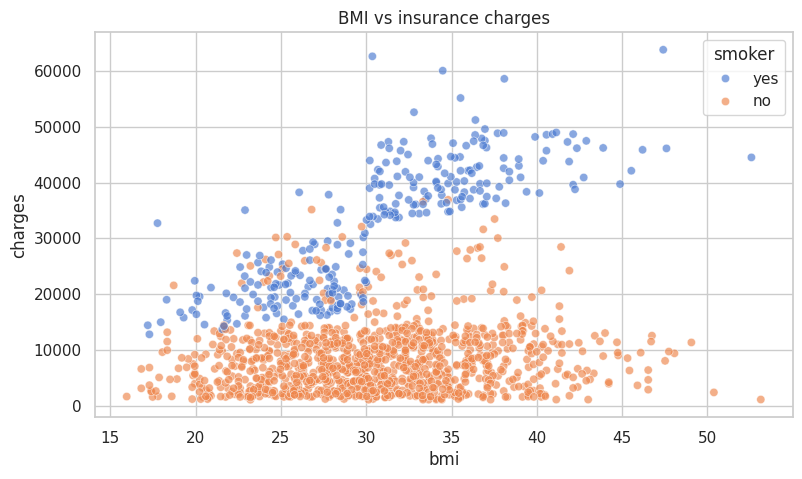

In [27]:
sns.scatterplot(data=df,x="bmi",y="charges",hue="smoker",alpha=.65); plt.title("BMI vs insurance charges"); plt.show()

## 28 · Children vs charges

Review the output and use it to guide the next analysis step.

,count,mean,median
children,,,
0,574,12365.98,9856.95
1,324,12731.17,8483.87
2,240,15073.56,9264.98
3,157,15355.32,10600.55
4,25,13850.66,11033.66
5,18,8786.04,8589.57


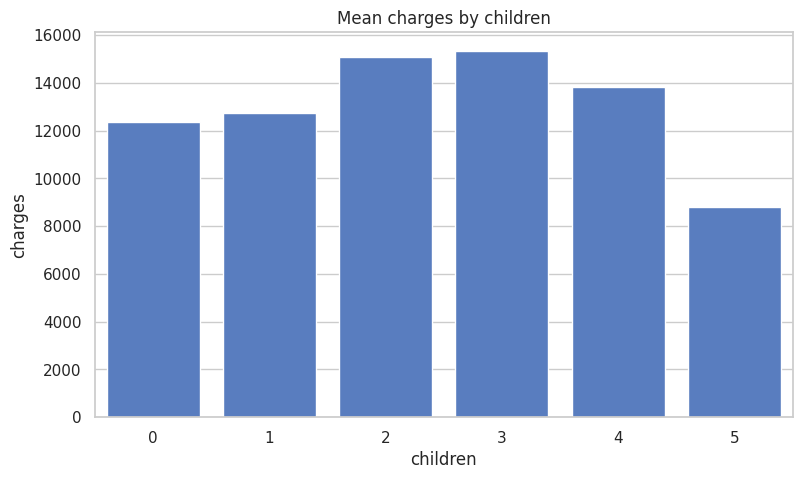

In [28]:
display(df.groupby("children").charges.agg(["count","mean","median"]).round(2))
sns.barplot(data=df,x="children",y="charges",errorbar=None); plt.title("Mean charges by children"); plt.show()

## 29 · Grouped cost summary

Explore this stage of the insurance-cost regression workflow.

In [29]:
display(df.groupby(["smoker","region"]).charges.agg(["count","mean","median","std"]).round(2))

count      mean    median       std
smoker region                                        
no     northeast    257   9165.53   8342.91   6157.20
       northwest    267   8556.46   7256.72   6128.55
       southeast    273   8032.22   6652.53   6137.33
       southwest    267   8019.28   7348.14   5489.51
yes    northeast     67  29673.54  28101.33  11589.56
       northwest     58  30192.00  27489.00  11413.83
       southeast     91  34845.00  37484.45  11324.77
       southwest     58  32269.06  35165.26  11270.28

## 30 · Correlation matrix

Review the output and use it to guide the next analysis step.

In [30]:
numeric_df=df.select_dtypes(include=np.number)
corr=numeric_df.corr()
display(corr.round(2))

,age,bmi,children,charges
age,1.00,0.11,0.04,0.30
bmi,0.11,1.00,0.01,0.20
children,0.04,0.01,1.00,0.07
charges,0.30,0.20,0.07,1.00


## 31 · Correlation heatmap

Explore this stage of the insurance-cost regression workflow.

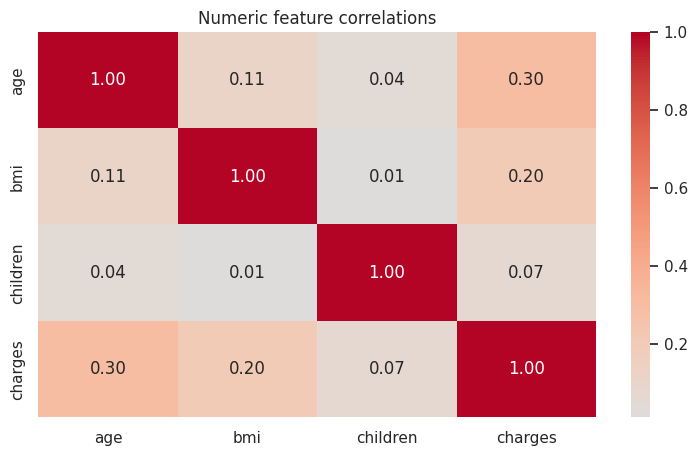

In [31]:
sns.heatmap(corr,annot=True,cmap="coolwarm",center=0,fmt=".2f"); plt.title("Numeric feature correlations"); plt.show()

## 32 · Separate features and target

Review the output and use it to guide the next analysis step.

In [32]:
X=df.drop(columns="charges").copy()
y=df["charges"].copy()
print("X:",X.shape,"y:",y.shape)

X: (1338, 6) y: (1338,)


## 33 · Identify feature types

Explore this stage of the insurance-cost regression workflow.

In [33]:
numeric_features=X.select_dtypes(include=np.number).columns.tolist()
categorical_features=X.select_dtypes(exclude=np.number).columns.tolist()
print(numeric_features,categorical_features)

['age', 'bmi', 'children'] ['sex', 'smoker', 'region']


## 34 · Train/test split

Review the output and use it to guide the next analysis step.

In [34]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,random_state=SEED)
print(len(X_train),"training |",len(X_test),"testing")

1070 training | 268 testing


## 35 · Build preprocessing pipeline

Explore this stage of the insurance-cost regression workflow.

In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
num_pipe=Pipeline([("imputer",SimpleImputer(strategy="median")),("scale",StandardScaler())])
cat_pipe=Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),("encode",OneHotEncoder(handle_unknown="ignore"))])
preprocessor=ColumnTransformer([("num",num_pipe,numeric_features),("cat",cat_pipe,categorical_features)])
print("Preprocessing ready")

Preprocessing ready


## 36 · Train Linear Regression

Review the output and use it to guide the next analysis step.

In [36]:
from sklearn.linear_model import LinearRegression
linear_model=Pipeline([("preprocessor",preprocessor),("regressor",LinearRegression())])
linear_model.fit(X_train,y_train)
print("Linear Regression trained")

Linear Regression trained


## 37 · Generate predictions

Explore this stage of the insurance-cost regression workflow.

In [37]:
y_pred=linear_model.predict(X_test)
display(pd.DataFrame({"actual":y_test.values,"predicted":y_pred}).head(10).round(2))

,actual,predicted
0,9095.07,8969.55
1,5272.18,7068.75
2,29330.98,36858.41
3,9301.89,9454.68
4,33750.29,26973.17
5,4536.26,10864.11
6,2117.34,170.28
7,14210.54,16903.45
8,3732.63,1092.43
9,10264.44,11218.34


## 38 · Evaluate Linear Regression

Review the output and use it to guide the next analysis step.

In [38]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
def regression_metrics(actual,pred,name):
    return {"Model":name,"MAE":mean_absolute_error(actual,pred),"RMSE":np.sqrt(mean_squared_error(actual,pred)),"R2":r2_score(actual,pred)}
linear_results=regression_metrics(y_test,y_pred,"Linear Regression")
display(pd.DataFrame([linear_results]).round(3))

,Model,MAE,RMSE,R2
0,Linear Regression,4181.194,5796.285,0.784


## 39 · Actual vs predicted

Explore this stage of the insurance-cost regression workflow.

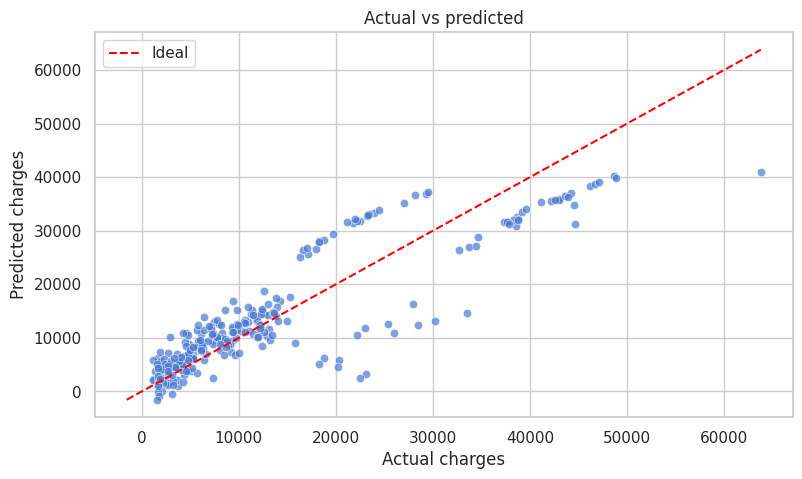

In [39]:
lo=min(y_test.min(),y_pred.min()); hi=max(y_test.max(),y_pred.max())
sns.scatterplot(x=y_test,y=y_pred,alpha=.7)
plt.plot([lo,hi],[lo,hi],"--",color="red",label="Ideal")
plt.xlabel("Actual charges"); plt.ylabel("Predicted charges"); plt.title("Actual vs predicted"); plt.legend(); plt.show()

## 40 · Residual diagnostics

Review the output and use it to guide the next analysis step.

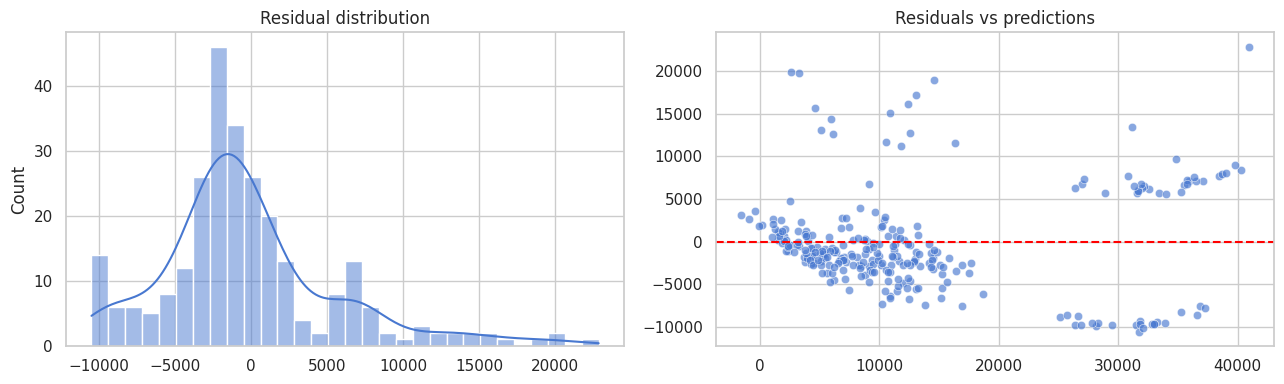

In [40]:
residuals=y_test.values-y_pred
fig,ax=plt.subplots(1,2,figsize=(13,4))
sns.histplot(residuals,bins=30,kde=True,ax=ax[0]); ax[0].set_title("Residual distribution")
sns.scatterplot(x=y_pred,y=residuals,ax=ax[1],alpha=.65); ax[1].axhline(0,color="red",ls="--"); ax[1].set_title("Residuals vs predictions")
plt.tight_layout(); plt.show()

## 41 · Log-target Linear Regression

Explore this stage of the insurance-cost regression workflow.

In [41]:
log_model=Pipeline([("preprocessor",preprocessor),("regressor",LinearRegression())])
log_model.fit(X_train,np.log1p(y_train))
log_pred=np.maximum(0,np.expm1(log_model.predict(X_test)))
log_results=regression_metrics(y_test,log_pred,"Log-target Linear Regression")
display(pd.DataFrame([linear_results,log_results]).round(3))

,Model,MAE,RMSE,R2
0,Linear Regression,4181.194,5796.285,0.784
1,Log-target Linear Regression,3888.443,7814.064,0.607


## 42 · Compare Ridge, Lasso and Random Forest

Review the output and use it to guide the next analysis step.

In [42]:
from sklearn.linear_model import Ridge,Lasso
from sklearn.ensemble import RandomForestRegressor
models={"Ridge":Ridge(alpha=1),"Lasso":Lasso(alpha=.01,max_iter=10000),"Random Forest":RandomForestRegressor(n_estimators=100,max_depth=8,min_samples_leaf=3,random_state=SEED,n_jobs=-1)}
results=[linear_results,log_results]
for name,est in models.items():
    pipe=Pipeline([("preprocessor",preprocessor),("regressor",est)])
    pipe.fit(X_train,y_train); results.append(regression_metrics(y_test,pipe.predict(X_test),name))
comparison_df=pd.DataFrame(results).sort_values("RMSE")
display(comparison_df.round(3))

,Model,MAE,RMSE,R2
4,Random Forest,2426.374,4388.627,0.876
0,Linear Regression,4181.194,5796.285,0.784
3,Lasso,4181.198,5796.287,0.784
2,Ridge,4186.913,5798.299,0.783
1,Log-target Linear Regression,3888.443,7814.064,0.607


## 43 · Interpret Linear Regression coefficients

Explore this stage of the insurance-cost regression workflow.

In [43]:
feature_names=linear_model.named_steps["preprocessor"].get_feature_names_out()
coef_df=pd.DataFrame({"feature":feature_names,"coefficient":linear_model.named_steps["regressor"].coef_})
coef_df["abs_coef"]=coef_df.coefficient.abs()
coef_df=coef_df.sort_values("abs_coef",ascending=False)
display(coef_df.drop(columns="abs_coef").head(20).round(3))

,feature,coefficient
6,cat__smoker_yes,11825.564
5,cat__smoker_no,-11825.564
0,num__age,3614.975
1,num__bmi,2036.228
2,num__children,516.890
7,cat__region_northeast,459.585
10,cat__region_southwest,-350.214
9,cat__region_southeast,-198.279
8,cat__region_northwest,88.908
3,cat__sex_female,9.296


## 44 · Visualize strongest coefficients

Review the output and use it to guide the next analysis step.

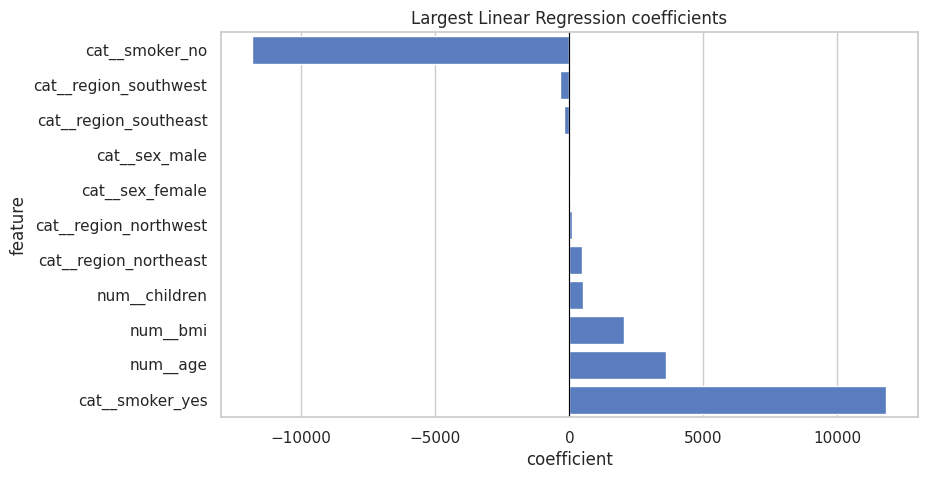

In [44]:
top=coef_df.head(15).sort_values("coefficient")
sns.barplot(data=top,x="coefficient",y="feature")
plt.axvline(0,color="black",lw=.8); plt.title("Largest Linear Regression coefficients"); plt.show()

## 45 · Final model summary

Explore this stage of the insurance-cost regression workflow.

In [45]:
best=comparison_df.iloc[0]
print("MEDICAL COST PERSONAL DATASETS · RESULTS")
print("="*48)
print("Rows:",len(df),"| Train:",len(X_train),"| Test:",len(X_test))
print(f"Linear Regression MAE:  ${linear_results['MAE']:,.2f}")
print(f"Linear Regression RMSE: ${linear_results['RMSE']:,.2f}")
print(f"Linear Regression R²:   {linear_results['R2']:.4f}")
print("Lowest RMSE in comparison:",best["Model"],f"(${best['RMSE']:,.2f})")
print("Educational analysis only; not a real-world underwriting tool.")

MEDICAL COST PERSONAL DATASETS · RESULTS
Rows: 1338 | Train: 1070 | Test: 268
Linear Regression MAE:  $4,181.19
Linear Regression RMSE: $5,796.28
Linear Regression R²:   0.7836
Lowest RMSE in comparison: Random Forest ($4,388.63)
Educational analysis only; not a real-world underwriting tool.



## FINAL TAKEAWAYS
A transparent baseline for understanding insurance-cost prediction

## What this notebook delivered
- Loaded and validated the `insurance.csv` dataset.
- Explored distributions, category frequencies, charges, and feature relationships.
- Built leakage-safe preprocessing with numeric scaling and categorical one-hot encoding.
- Trained and evaluated **Linear Regression** on a held-out test set.
- Examined predictions, residuals, and model coefficients.
- Compared Linear Regression with a log-target variant, Ridge, Lasso, and a compact Random Forest baseline.

## Interpretation reminders
1. **Association is not causation.** Observed relationships do not prove a feature causes higher or lower charges.
2. **A single split is not the whole story.** Repeated cross-validation can provide a more stable estimate.
3. **Fairness matters.** Demographic attributes can create ethical and regulatory concerns in insurance applications.
4. **Coefficient interpretation requires care.** Numeric inputs are standardized and categorical inputs are one-hot encoded.
5. **Generalization is limited.** This historical dataset may not represent other populations, countries, insurers, or time periods.

## Suggested next experiments
- Use repeated K-fold cross-validation.
- Add carefully selected interaction terms, such as smoking status × BMI.
- Compare errors across meaningful subgroups.
- Validate on a genuinely external dataset before considering practical use.

---

<div align="center">
**Created by Mobeen Fatima · @mobeenfatimah**

*Explore the data. Understand the model. Evaluate responsibly.*
</div>